In [1]:
import numpy as np
import matplotlib.pyplot as plt
from stable_baselines3 import PPO
from stable_baselines3.common.callbacks import StopTrainingOnMaxEpisodes
from stable_baselines3.common.env_util import make_vec_env
from stable_baselines3.common.vec_env import DummyVecEnv, VecNormalize
from stable_baselines3.common.monitor import Monitor
import torch as th
import os

In [2]:
import gym
import gym_mppt
from gym import envs
env = gym.make("mppt_shaded-v3")

num_obs = env.observation_space.shape[0]
print("Size of Observation Space ->  {}".format(num_obs))
print(env.observation_space)

print()

num_actions = env.action_space.shape[0]
print("Size of Action Space ->  {}".format(num_actions))
print(env.action_space)

Size of Observation Space ->  8
Box([  0.   0.   0. -inf -inf -inf -inf -inf], [212.  inf  inf  inf  inf  inf  inf  inf], (8,), float32)

Size of Action Space ->  1
Box([-5.], [5.], (1,), float32)


C:\Users\archi\anaconda3\envs\BTPtorch\lib\site-packages\gym\spaces\box.py:73: UserWarning: WARN: Box bound precision lowered by casting to float32
  logger.warn(


In [3]:
env = make_vec_env("mppt_shaded-v3", n_envs=1)

# Custom MLP policy of two layers of size 32 each with Relu activation function
policy_kwargs = dict(activation_fn=th.nn.ReLU, net_arch=[64] * 2)

# Create the agent
model = PPO("MlpPolicy",
            env,
            batch_size=int(128),
            n_epochs=10,
            learning_rate=1e-3,
            gamma=0.5,
            clip_range=0.1,
            n_steps=4096,
            policy_kwargs=policy_kwargs,
            verbose=1,
            device="cuda")

model.learn(total_timesteps=int(100*10000), progress_bar=True, reset_num_timesteps=False)

Output()

Using cuda device
---------------------------------
| rollout/           |          |
|    ep_len_mean     | 100      |
|    ep_rew_mean     | -86.5    |
| time/              |          |
|    fps             | 368      |
|    iterations      | 1        |
|    time_elapsed    | 11       |
|    total_timesteps | 4096     |
---------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -86.9        |
| time/                   |              |
|    fps                  | 333          |
|    iterations           | 2            |
|    time_elapsed         | 24           |
|    total_timesteps      | 8192         |
| train/                  |              |
|    approx_kl            | 0.0052416343 |
|    clip_fraction        | 0.101        |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.41        |
|    explained_variance   | -5.43       

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -63.5        |
| time/                   |              |
|    fps                  | 305          |
|    iterations           | 11           |
|    time_elapsed         | 147          |
|    total_timesteps      | 45056        |
| train/                  |              |
|    approx_kl            | 0.0018937101 |
|    clip_fraction        | 0.0268       |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.37        |
|    explained_variance   | -0.122       |
|    learning_rate        | 0.001        |
|    loss                 | 0.181        |
|    n_updates            | 100          |
|    policy_gradient_loss | 0.00432      |
|    std                  | 0.954        |
|    value_loss           | 0.428        |
------------------------------------------
------------------------------------------
| rollout/ 

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 100        |
|    ep_rew_mean          | -56.1      |
| time/                   |            |
|    fps                  | 291        |
|    iterations           | 20         |
|    time_elapsed         | 281        |
|    total_timesteps      | 81920      |
| train/                  |            |
|    approx_kl            | 0.08655856 |
|    clip_fraction        | 0.0361     |
|    clip_range           | 0.1        |
|    entropy_loss         | -1.36      |
|    explained_variance   | 0.309      |
|    learning_rate        | 0.001      |
|    loss                 | 0.113      |
|    n_updates            | 190        |
|    policy_gradient_loss | -0.00144   |
|    std                  | 0.94       |
|    value_loss           | 0.242      |
----------------------------------------
----------------------------------------
| rollout/                |            |
|    ep_len_mean

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 100        |
|    ep_rew_mean          | -53        |
| time/                   |            |
|    fps                  | 279        |
|    iterations           | 29         |
|    time_elapsed         | 424        |
|    total_timesteps      | 118784     |
| train/                  |            |
|    approx_kl            | 0.01953565 |
|    clip_fraction        | 0.0595     |
|    clip_range           | 0.1        |
|    entropy_loss         | -1.34      |
|    explained_variance   | 0.312      |
|    learning_rate        | 0.001      |
|    loss                 | 0.0871     |
|    n_updates            | 280        |
|    policy_gradient_loss | -0.00155   |
|    std                  | 0.923      |
|    value_loss           | 0.19       |
----------------------------------------
------------------------------------------
| rollout/                |              |
|    ep_len_

...

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 100        |
|    ep_rew_mean          | -29.3      |
| time/                   |            |
|    fps                  | 225        |
|    iterations           | 209        |
|    time_elapsed         | 3792       |
|    total_timesteps      | 856064     |
| train/                  |            |
|    approx_kl            | 0.06630748 |
|    clip_fraction        | 0.115      |
|    clip_range           | 0.1        |
|    entropy_loss         | -1.22      |
|    explained_variance   | 0.399      |
|    learning_rate        | 0.001      |
|    loss                 | 0.0595     |
|    n_updates            | 2080       |
|    policy_gradient_loss | -0.000105  |
|    std                  | 0.819      |
|    value_loss           | 0.128      |
----------------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_me

----------------------------------------
| rollout/                |            |
|    ep_len_mean          | 100        |
|    ep_rew_mean          | -26.7      |
| time/                   |            |
|    fps                  | 224        |
|    iterations           | 218        |
|    time_elapsed         | 3970       |
|    total_timesteps      | 892928     |
| train/                  |            |
|    approx_kl            | 0.03981208 |
|    clip_fraction        | 0.113      |
|    clip_range           | 0.1        |
|    entropy_loss         | -1.23      |
|    explained_variance   | 0.368      |
|    learning_rate        | 0.001      |
|    loss                 | 0.0587     |
|    n_updates            | 2170       |
|    policy_gradient_loss | -0.000439  |
|    std                  | 0.824      |
|    value_loss           | 0.131      |
----------------------------------------
-----------------------------------------
| rollout/                |             |
|    ep_len_me

-----------------------------------------
| rollout/                |             |
|    ep_len_mean          | 100         |
|    ep_rew_mean          | -29.7       |
| time/                   |             |
|    fps                  | 224         |
|    iterations           | 227         |
|    time_elapsed         | 4138        |
|    total_timesteps      | 929792      |
| train/                  |             |
|    approx_kl            | 0.003124997 |
|    clip_fraction        | 0.114       |
|    clip_range           | 0.1         |
|    entropy_loss         | -1.24       |
|    explained_variance   | 0.379       |
|    learning_rate        | 0.001       |
|    loss                 | 0.0499      |
|    n_updates            | 2260        |
|    policy_gradient_loss | 0.000913    |
|    std                  | 0.837       |
|    value_loss           | 0.107       |
-----------------------------------------
-----------------------------------------
| rollout/                |       

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -25.4        |
| time/                   |              |
|    fps                  | 224          |
|    iterations           | 236          |
|    time_elapsed         | 4304         |
|    total_timesteps      | 966656       |
| train/                  |              |
|    approx_kl            | 0.0072288136 |
|    clip_fraction        | 0.136        |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.24        |
|    explained_variance   | 0.239        |
|    learning_rate        | 0.001        |
|    loss                 | 0.0473       |
|    n_updates            | 2350         |
|    policy_gradient_loss | 0.00146      |
|    std                  | 0.833        |
|    value_loss           | 0.109        |
------------------------------------------
------------------------------------------
| rollout/ 

------------------------------------------
| rollout/                |              |
|    ep_len_mean          | 100          |
|    ep_rew_mean          | -25.9        |
| time/                   |              |
|    fps                  | 224          |
|    iterations           | 245          |
|    time_elapsed         | 4477         |
|    total_timesteps      | 1003520      |
| train/                  |              |
|    approx_kl            | 0.0040329783 |
|    clip_fraction        | 0.131        |
|    clip_range           | 0.1          |
|    entropy_loss         | -1.2         |
|    explained_variance   | 0.311        |
|    learning_rate        | 0.001        |
|    loss                 | 0.0395       |
|    n_updates            | 2440         |
|    policy_gradient_loss | 0.000449     |
|    std                  | 0.804        |
|    value_loss           | 0.0957       |
------------------------------------------


In [4]:
dire = os.getcwd()
model.save(dire + '\\ppo_trained_model3')

### Evaluation

In [3]:
dire = os.getcwd()
env = make_vec_env("mppt_shaded-v3", n_envs=1)
env.training = False
model = PPO.load(dire + '\\ppo_trained_model3')
model.set_env(env)

1
2
3
4
5
6
7
8
9
10


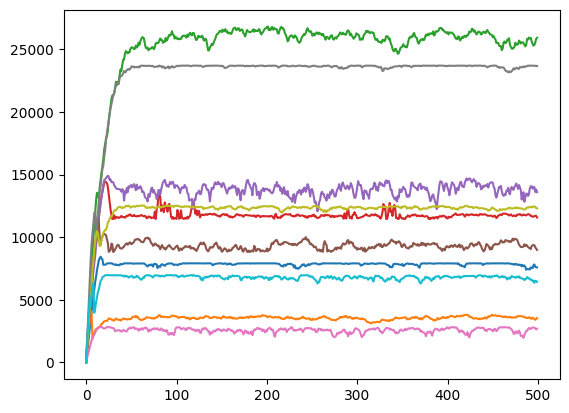

In [11]:
for j in range(10):
    print(j+1)
    obs = env.reset()
    powlst = []
    normpowlst = []
    for i in range(500):
        action, _state = model.predict(obs)
        obs, rewards, done, info = env.step(action)
        powlst.append(info[0]["Power"])
        normpowlst.append(info[0]["NormPower"])
#     plt.plot(normpowlst)
    plt.plot(powlst)

1
2
3
4
5
6
7
8
9
10


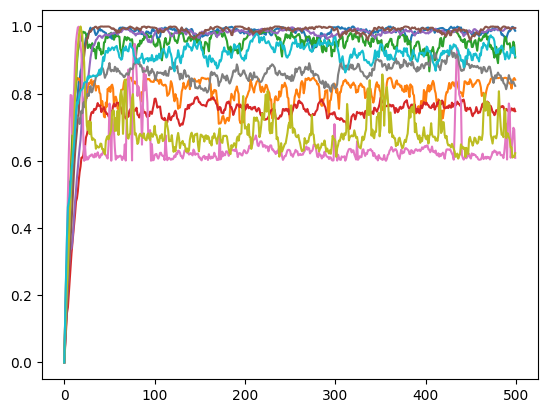

In [12]:
for j in range(10):
    print(j+1)
    obs = env.reset()
    powlst = []
    normpowlst = []
    for i in range(500):
        action, _state = model.predict(obs)
        obs, rewards, done, info = env.step(action)
        powlst.append(info[0]["Power"])
        normpowlst.append(info[0]["NormPower"])
    plt.plot(normpowlst)
#     plt.plot(powlst)

In [7]:
obs = env.reset()
perf = []
for x in range(1, 11):
    for y in range(1, 11):
        for z in range(1, 11):
            obs = env.reset()
            obs = env.render([x, 10, y, 10, z, 10, 25, 1000])
            powlst = []
            normpowlst = []
            for i in range(500):
                action, _state = model.predict(obs)
                obs, rewards, done, info = env.step(action)
                normpowlst.append(float(info[0]["NormPower"]))
            print(x, y, z, sum(normpowlst)/5)
            perf.append(sum(normpowlst)/5)

1 1 1 41.40376426577568
1 1 2 40.42036133408546
1 1 3 48.76792118549347
1 1 4 85.41895939707756
1 1 5 97.69924397021532
1 1 6 93.25269317030907
1 1 7 84.10113316476345
1 1 8 77.17559050023556
1 1 9 73.11416818499565
1 1 10 70.83402088284492
1 2 1 39.379415399578434
1 2 2 32.51665506958962
1 2 3 39.34533322155475
1 2 4 77.82351505676438
1 2 5 98.31597712337971
1 2 6 93.78711771517992
1 2 7 84.35888676345348
1 2 8 77.51938554048539
1 2 9 73.00032898932696
1 2 10 71.20137905744566
1 3 1 45.48313692212105
1 3 2 43.44208550155163
1 3 3 39.90448832809925
1 3 4 52.908574116230014
1 3 5 74.41719410400837
1 3 6 84.69858336614676
1 3 7 84.9383494347334
1 3 8 78.03019332587719
1 3 9 73.25130707323551
1 3 10 71.5519797846675
1 4 1 72.27760171890259
1 4 2 72.39126735925674
1 4 3 61.936722186207774
1 4 4 65.92508216947317
1 4 5 57.45207627117634
1 4 6 64.37359925312782
1 4 7 66.34954283088446
1 4 8 67.51742349117994
1 4 9 67.64312260076403
1 4 10 67.10184431346133
1 5 1 89.92175200246274
1 5 2 89.80

4 4 10 45.669871888198294
4 5 1 59.90846733897924
4 5 2 60.34353016138889
4 5 3 59.40067647770047
4 5 4 50.00956078022718
4 5 5 58.89143833741546
4 5 6 62.6337013207376
4 5 7 64.35948869138956
4 5 8 63.564127303659916
4 5 9 64.46300456523895
4 5 10 63.63451593816281
4 6 1 76.3156770259142
4 6 2 76.23432072103023
4 6 3 75.91447515636682
4 6 4 63.05650164783001
4 6 5 65.80268328934908
4 6 6 80.25027080774308
4 6 7 84.02951599545777
4 6 8 85.80270262658595
4 6 9 86.54116115123034
4 6 10 86.03145961910487
4 7 1 85.49624065142125
4 7 2 85.45692642778158
4 7 3 85.2442450878161
4 7 4 71.01457923315465
4 7 5 68.67467659935355
4 7 6 88.53028958588838
4 7 7 96.75730665961164
4 7 8 96.94543065950275
4 7 9 97.29144158212152
4 7 10 97.15998148921662
4 8 1 89.18445151150226
4 8 2 89.28556676357985
4 8 3 89.41375937610864
4 8 4 74.03190040592166
4 8 5 71.45429027229548
4 8 6 91.4118474677205
4 8 7 97.30670618601144
4 8 8 96.77108979821205
4 8 9 96.4265803784132
4 8 10 96.30322300310104
4 9 1 83.62614

7 9 1 90.53002955988049
7 9 2 90.6149989016354
7 9 3 91.238829151541
7 9 4 90.88508300632239
7 9 5 91.26781354323029
7 9 6 80.3899867206812
7 9 7 81.10375028513371
7 9 8 81.75051838457584
7 9 9 82.5220879562199
7 9 10 81.90523130744695
7 10 1 91.13461272716522
7 10 2 90.74958031087291
7 10 3 90.8194561779499
7 10 4 90.87757332324982
7 10 5 91.75152209028602
7 10 6 81.58027731329203
7 10 7 80.9675097040832
7 10 8 82.39366624131799
7 10 9 82.45462703406811
7 10 10 82.41237376704812
8 1 1 89.11616492420436
8 1 2 89.15027180165052
8 1 3 89.57708542644977
8 1 4 89.67902253682237
8 1 5 88.1671785221358
8 1 6 93.6913974314928
8 1 7 96.42163461372256
8 1 8 96.44076357334852
8 1 9 96.18068173360079
8 1 10 96.47683148101221
8 2 1 89.49024474620819
8 2 2 89.1958823679015
8 2 3 89.52087936848402
8 2 4 89.9670564904809
8 2 5 88.79934502914548
8 2 6 94.21307060512532
8 2 7 96.53011195063591
8 2 8 96.62262558490038
8 2 9 96.39143902361393
8 2 10 96.19110304117203
8 3 1 90.08516969680787
8 3 2 89.7018

In [8]:
np.average(perf)

81.84761494855803